In [47]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

import joblib

print("Libraries imported successfully!")

Libraries imported successfully!


In [48]:
df = pd.read_csv("../data/Telco-Customer-Churn-Processed.csv")

print("Dataset loaded successfully!")
print("Rows: ", df.shape[0])
print("Columns: ", df.shape[1])

df.head()

Dataset loaded successfully!
Rows:  7043
Columns:  21


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [49]:
# Check the dataset
print("Dataset shape: ", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

print("\nChurn distribution:")
print(df["Churn"].value_counts())

Dataset shape:  (7043, 21)

Column names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Missing values:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Churn distribution:
Churn
No     5174
Yes    1869
Name: count, dtype: int64


In [50]:
# Remove customer ID because it does not help predict churn

if "customerID" in df.columns:
    df = df.drop(columns=["customerID"])

print("Remaining columns:")
print(df.columns.tolist())

Remaining columns:
['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


In [51]:
# Target variable
y = df["Churn"].map({
    "No": 0,
    "Yes": 1
})

#Features
X = df.drop(columns=["Churn"])

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

X shape: (7043, 19)
y shape: (7043,)

Target distribution:
Churn
0    5174
1    1869
Name: count, dtype: int64


In [52]:
# Identify numerical and categorical columns

numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numerical features:")
print(numerical_features)

print("\nCategorical features:")
print(categorical_features)

Numerical features:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


C:\Users\User\AppData\Local\Temp\ipykernel_2316\2771612710.py:7: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(


In [53]:
# Preprocessing for numerical columns

numerical_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        )
    ]
)


# Preprocessing for categorical columns

categorical_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore"
            )
        )
    ]
)


# Combine preprocessing

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            numerical_transformer,
            numerical_features
        ),
        (
            "cat",
            categorical_transformer,
            categorical_features
        )
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [54]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (5634, 19)
Testing data: (1409, 19)


In [55]:
model = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "classifier",
            LogisticRegression(
                max_iter=1000
            )
        )
    ]
)

print("Machine learning model created successfully!")

Machine learning model created successfully!


In [56]:
model.fit(
    X_train,
    y_train
)

print("Model taining copmpleted successfully")

Model taining copmpleted successfully


c:\Users\User\Desktop\Customer Churn Intelligence\venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [57]:
y_pred = model.predict(X_test)

y_probability = model.predict_proba(X_test)[:, 1]

print("Predictions generated successfully!")

print("\nFirst 10 predictions:")
print(y_pred[:10])

print("\nFirst 10 churn probabilities:")
print(y_probability[:10])

Predictions generated successfully!

First 10 predictions:
[0 1 0 0 0 1 0 0 0 0]

First 10 churn probabilities:
[0.04584073 0.68165195 0.06317562 0.38931306 0.02038691 0.60128282
 0.44009532 0.12644416 0.00261425 0.39645108]


In [58]:
accuracy = accuracy_score(
    y_test,
    y_pred
)

roc_auc = roc_auc_score(
    y_test,
    y_probability
)

print(
    f"Accuracy: {accuracy:.4f}"
)

print(
    f"ROC-AUC Score: {roc_auc:.4f}"
)

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred
    )
)

Accuracy: 0.8055
ROC-AUC Score: 0.8428

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.89      0.87      1035
           1       0.66      0.56      0.61       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



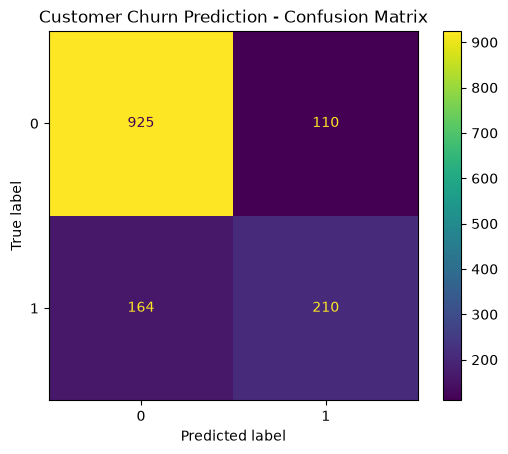

In [59]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred
)

plt.title("Customer Churn Prediction - Confusion Matrix")
plt.show()

In [60]:
from pathlib import Path

models_folder = Path("../models")

models_folder.mkdir(
    exist_ok=True
)

model_path = (
    models_folder
    / "churn_model.pkl"
)

joblib.dump(
    model,
    model_path
)

print(
    f"✅ Model saved successfully at: {model_path}"
)

✅ Model saved successfully at: ..\models\churn_model.pkl


In [61]:
from sklearn.ensemble import RandomForestClassifier

In [62]:
random_forest_model = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=200,
                random_state=42,
                class_weight="balanced"
            )
        )
    ]
)

random_forest_model.fit(
    X_train,
    y_train
)

print("Random Forest training completed!")

Random Forest training completed!


In [63]:
rf_predictions = random_forest_model.predict(
    X_test
)

rf_probabilities = (
    random_forest_model
    .predict_proba(X_test)[:, 1]
)

rf_accuracy = accuracy_score(
    y_test,
    rf_predictions
)

rf_roc_auc = roc_auc_score(
    y_test,
    rf_probabilities
)

print(
    f"Random Forest Accuracy: {rf_accuracy:.4f}"
)

print(
    f"Random Forest ROC-AUC: {rf_roc_auc:.4f}"
)

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        rf_predictions
    )
)

Random Forest Accuracy: 0.7708
Random Forest ROC-AUC: 0.8229

Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.82      0.84      1035
           1       0.56      0.64      0.60       374

    accuracy                           0.77      1409
   macro avg       0.71      0.73      0.72      1409
weighted avg       0.78      0.77      0.78      1409



In [64]:
comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest"
    ],
    "Accuracy": [
        accuracy,
        rf_accuracy
    ],
    "ROC-AUC": [
        roc_auc,
        rf_roc_auc
    ]
})

comparison

,Model,Accuracy,ROC-AUC
0,Logistic Regression,0.805536,0.842765
1,Random Forest,0.770759,0.822946


In [68]:
%pip install plotly

  Using cached plotly-7.1.0-py3-none-any.whl.metadata (8.8 kB)
Using cached plotly-7.1.0-py3-none-any.whl (9.7 MB)
Note: you may need to restart the kernel to use updated packages.


In [69]:
import plotly.express as px

# Your existing code
fig = px.bar(
    comparison,
    x="Model",
    y="ROC-AUC",
    title="Model Comparison - ROC-AUC",
    text_auto=".3f"
)

fig.update_yaxes(range=[0, 1])
fig.show()

In [70]:
if rf_roc_auc > roc_auc:

    best_model = random_forest_model
    best_model_name = "Random Forest"
    best_score = rf_roc_auc

else:

    best_model = model
    best_model_name = "Logistic Regression"
    best_score = roc_auc


print(
    f"Best Model: {best_model_name}"
)

print(
    f"Best ROC-AUC: {best_score:.4f}"
)

Best Model: Logistic Regression
Best ROC-AUC: 0.8428


In [71]:
best_model_path = (
    models_folder
    / "churn_model.pkl"
)

joblib.dump(
    best_model,
    best_model_path
)

print(
    f"✅ Best model saved to: {best_model_path}"
)

✅ Best model saved to: ..\models\churn_model.pkl
